# 04 — H1: Did energy-intensive firms reduce carbon intensity more after 2022?

**H1:** After the 2022 energy price shock, firms with high pre-crisis energy intensity reduced
their carbon intensity more than firms with low pre-crisis energy intensity.

**Design:** two-way fixed effects difference-in-differences (TWFE DiD)

$$\ln(CI_{it}) = \alpha_i + \lambda_t + \beta\,(Post_t \times Exposure_i) + \varepsilon_{it}$$

* $\alpha_i$ firm fixed effects, $\lambda_t$ year fixed effects, standard errors clustered by firm
* $Exposure_i$: above-median pre-crisis (2016-2019) energy intensity (main) or its standardised log (continuous)
* $\beta < 0$ supports H1

The shock hits all firms in the same year (no staggered adoption), so the standard TWFE estimator
is appropriate. The event study tests the parallel-trends assumption (reference year 2019).

In [1]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyfixest as pf
import sample as S

TAB, FIG = Path("output/tables"), Path("output/figures")
TAB.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

p = S.load_panel()
h1 = S.main_sample(p)
h1["ln_assets"] = np.log(h1.total_assets.where(h1.total_assets > 0))
h1["post_high"] = h1.post * h1.high_exposure
h1["post_exp"] = h1.post * h1.exposure_std
ind = h1[h1.industry].copy()
print(f"H1 sample: {h1.ric.nunique()} firms, {len(h1)} firm-years | industry subsample: {ind.ric.nunique()} firms")

H1 sample: 387 firms, 3214 firm-years | industry subsample: 231 firms


## 1. Main estimates

In [2]:
VC = {"CRV1": "ric"}
m1 = pf.feols("ln_ci ~ post_high | ric + fyear", data=h1, vcov=VC)
m2 = pf.feols("ln_ci ~ post_exp | ric + fyear", data=h1, vcov=VC)
m3 = pf.feols("ln_ci ~ post_high + ln_assets | ric + fyear", data=h1, vcov=VC)
m4 = pf.feols("ln_ci ~ post_high | ric + fyear", data=ind, vcov=VC)
models = [m1, m2, m3, m4]
pf.etable(models, labels={"post_high": "Post x High exposure", "post_exp": "Post x Exposure (std.)",
                          "ln_assets": "ln(total assets)", "ln_ci": "ln(carbon intensity)"},
          model_heads=["Main", "Continuous", "Size control", "Industry only"])

GT(_tbl_data=  __index_level_0__       __index_level_1__                      0  \
0              coef    Post x High exposure  -0.209** <br> (0.069)   
1              coef  Post x Exposure (std.)                          
2              coef        ln(total assets)                          
3                fe                   fyear                      -   
4                fe                     ric                      -   
5             stats            Observations                  3,214   
6             stats                      R²                   0.93   

                       1                      2                       3  
0                         -0.211** <br> (0.070)  -0.265*** <br> (0.078)  
1  -0.161** <br> (0.052)                                                 
2                           -0.058 <br> (0.084)                          
3                      -                      -                       -  
4                      -                      -                       -  
5                  3,214                  3,214                   1,945  
6                  0.931                   0.93                   0.944  , _body=<great_tables._gt_data.Body object at 0x00000238259C7B60>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align=None, column_width=None, stub_level=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None, stub_level=0), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(1)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(2)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='2', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(3)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='3', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(4)'), column_align='center', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x0000023825B13D90>, _spanners=Spanners([SpannerInfo(spanner_id='ln(carbon intensity)', spanner_level=2, spanner_label=Html(text='ln(carbon intensity)'), spanner_units=None, spanner_pattern=None, vars=['0', '1', '2', '3'], built=None), SpannerInfo(spanner_id='Main', spanner_level=1, spanner_label=Html(text='Main'), spanner_units=None, spanner_pattern=None, vars=['0'], built=None), SpannerInfo(spanner_id='Continuous', spanner_level=1, spanner_label=Html(text='Continuous'), spanner_units=None, spanner_pattern=None, vars=['1'], built=None), SpannerInfo(spanner_id='Size control', spanner_level=1, spanner_label=Html(text='Size control'), spanner_units=None, spanner_pattern=None, vars=['2'], built=None), SpannerInfo(spanner_id='Industry only', spanner_level=1, spanner_label=Html(text='Industry only'), spanner_units=None, spanner_pattern=None, vars=['3'], built=None)]), _heading=Heading(title=None, subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x0000023825C6C1A0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x0000023825B13250>, _source_notes=[Html(text='Significance levels: * p &lt; 0.05, ** p &lt; 0.01, *** p &lt; 0.001. Format of coefficient cell: Coefficient   (Std. Error)')], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x0000023825C6C2F0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x0000023825C6C6E0>, <great_tables._gt_data.FormatInfo object at 0x0000023825B13750>, <great_tables._gt_data.FormatInfo object at 0x0000023825B13B10>, <great_tables._gt_data.FormatInfo object at 0x00000238259DB100>, <great_tables._gt_data.FormatInfo object at 0x0000023825C682B0>, <great_tables._gt_data.FormatInfo object at 0x0000023825B1ED50>], _substitutions=[], _col_merge=[], _transforms

In [3]:
def coef_row(m, name, label):
    t = m.tidy().loc[name]
    return {"model": label, "coef": t["Estimate"], "se": t["Std. Error"], "p": t["Pr(>|t|)"],
            "ci_low": t["2.5%"], "ci_high": t["97.5%"], "pct_effect": 100 * (np.exp(t["Estimate"]) - 1),
            "N": m._N, "firms": h1.ric.nunique() if label != "Industry only" else ind.ric.nunique()}

main = pd.DataFrame([coef_row(m1, "post_high", "Main"), coef_row(m2, "post_exp", "Continuous"),
                     coef_row(m3, "post_high", "Size control"), coef_row(m4, "post_high", "Industry only")])
main.to_csv(TAB / "h1_main.csv", index=False)
pf.etable(models, type="tex", file_name=str(TAB / "h1_main.tex"),
          labels={"post_high": "Post $\\times$ High exposure", "post_exp": "Post $\\times$ Exposure (std.)",
                  "ln_assets": "ln(total assets)", "ln_ci": "ln(carbon intensity)"})
main

,model,coef,se,p,ci_low,ci_high,pct_effect,N,firms
0,Main,-0.208572,0.068936,0.002648,-0.344109,-0.073035,-18.825727,3214,387
1,Continuous,-0.160594,0.052086,0.002195,-0.263002,-0.058186,-14.836203,3214,387
2,Size control,-0.210738,0.069713,0.002671,-0.347802,-0.073673,-19.001338,3214,387
3,Industry only,-0.265446,0.077780,0.000760,-0.418699,-0.112194,-23.313621,1945,231


`pct_effect` translates the log coefficient into a percentage difference: (exp(beta) - 1) x 100.
Note on the size control: total assets may itself respond to the shock (a "bad control"), so the
specification without it is the main one.

## 2. Event study (parallel-trends test)
$$\ln(CI_{it}) = \alpha_i + \lambda_t + \sum_{k \neq 2019} \beta_k\, 1[t = k] \times High_i + \varepsilon_{it}$$

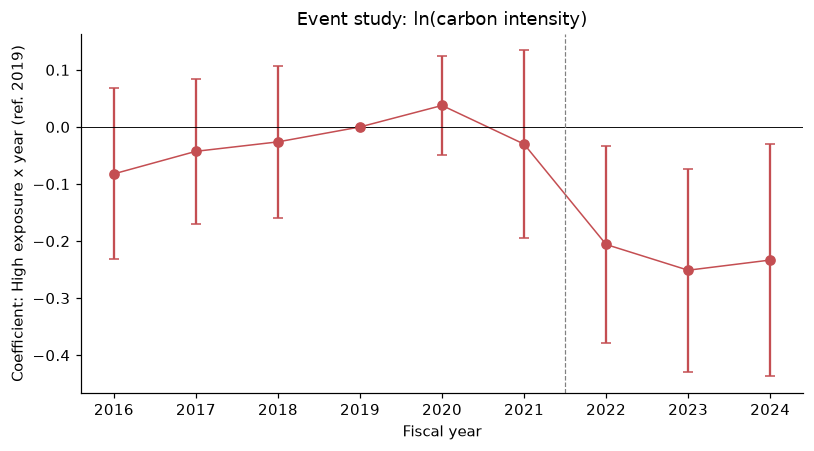

,year,Estimate,Std. Error,Pr(>|t|)
0,2016,-0.082194,0.076162,0.281174
1,2017,-0.042699,0.064568,0.508812
2,2018,-0.026145,0.067812,0.700042
0,2019,0.000000,NaN,NaN
3,2020,0.037653,0.044119,0.393942
4,2021,-0.030062,0.083464,0.718906
5,2022,-0.205942,0.087734,0.019412
6,2023,-0.251042,0.090320,0.005711
7,2024,-0.233224,0.103652,0.025007


In [4]:
es = pf.feols("ln_ci ~ i(fyear, high_exposure, ref=2019) | ric + fyear", data=h1, vcov=VC)
td = es.tidy().reset_index()
td["year"] = td["Coefficient"].str.extract(r"(\d{4})").astype(int)
td = pd.concat([td, pd.DataFrame([{"year": 2019, "Estimate": 0.0, "2.5%": 0.0, "97.5%": 0.0}])]).sort_values("year")
td[["year", "Estimate", "Std. Error", "2.5%", "97.5%", "Pr(>|t|)"]].to_csv(TAB / "h1_event_study.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.errorbar(td.year, td.Estimate, yerr=[td.Estimate - td["2.5%"], td["97.5%"] - td.Estimate],
            fmt="o", color="#C44E52", capsize=3)
ax.plot(td.year, td.Estimate, color="#C44E52", lw=1)
ax.axhline(0, color="k", lw=0.6); ax.axvline(2021.5, color="grey", ls="--", lw=0.8)
ax.set_xlabel("Fiscal year"); ax.set_ylabel("Coefficient: High exposure x year (ref. 2019)")
ax.set_title("Event study: ln(carbon intensity)")
fig.tight_layout(); fig.savefig(FIG / "h1_event_study.pdf"); plt.show()
td[["year", "Estimate", "Std. Error", "Pr(>|t|)"]]

### Joint test of pre-period coefficients
H0: all pre-2022 event-study coefficients are zero (parallel pre-trends).

In [5]:
coefs = es.coef(); names = [c for c in coefs.index if any(str(y) in c for y in [2016, 2017, 2018, 2020, 2021])]
names_strict = [c for c in names if any(str(y) in c for y in [2016, 2017, 2018])]
def wald(names):
    b = coefs[names].values; V = es._vcov[np.ix_([list(coefs.index).index(n) for n in names],
                                                  [list(coefs.index).index(n) for n in names])]
    stat = float(b @ np.linalg.inv(V) @ b) / len(names)
    from scipy import stats
    return stat, 1 - stats.f.cdf(stat, len(names), h1.ric.nunique() - 1)
f_all, p_all = wald(names); f_strict, p_strict = wald(names_strict)
pre = pd.DataFrame([{"test": "2016-2018, 2020-2021 = 0", "F": f_all, "p": p_all},
                    {"test": "2016-2018 = 0 (before COVID)", "F": f_strict, "p": p_strict}])
pre.to_csv(TAB / "h1_pretrend_test.csv", index=False)
pre

,test,F,p
0,"2016-2018, 2020-2021 = 0",0.548386,0.739560
1,2016-2018 = 0 (before COVID),0.471491,0.702324


## 3. Continuous-exposure event study

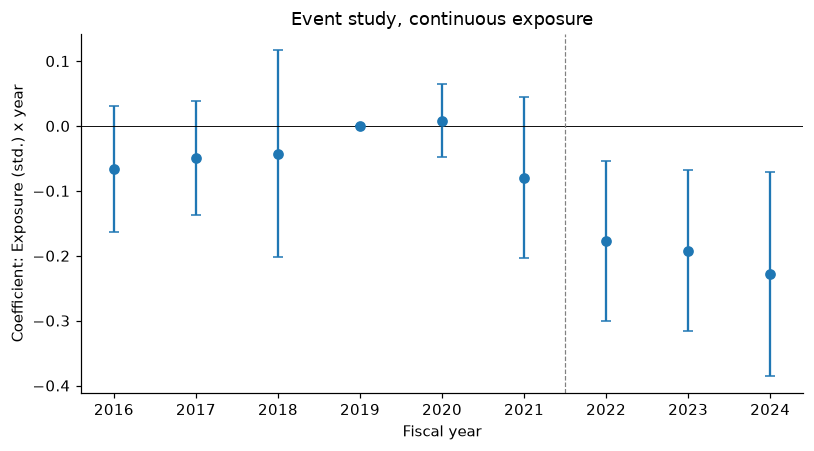

In [6]:
es_c = pf.feols("ln_ci ~ i(fyear, exposure_std, ref=2019) | ric + fyear", data=h1, vcov=VC)
tc = es_c.tidy().reset_index(); tc["year"] = tc["Coefficient"].str.extract(r"(\d{4})").astype(int)
tc = pd.concat([tc, pd.DataFrame([{"year": 2019, "Estimate": 0.0, "2.5%": 0.0, "97.5%": 0.0}])]).sort_values("year")
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.errorbar(tc.year, tc.Estimate, yerr=[tc.Estimate - tc["2.5%"], tc["97.5%"] - tc.Estimate], fmt="o", capsize=3)
ax.axhline(0, color="k", lw=0.6); ax.axvline(2021.5, color="grey", ls="--", lw=0.8)
ax.set_xlabel("Fiscal year"); ax.set_ylabel("Coefficient: Exposure (std.) x year")
ax.set_title("Event study, continuous exposure")
fig.tight_layout(); fig.savefig(FIG / "h1_event_study_continuous.pdf"); plt.show()

## 4. Summary
The cell below prints the key numbers used in the results chapter.

In [7]:
b = main.set_index("model")
print(f"Main: beta = {b.loc['Main','coef']:.3f} (SE {b.loc['Main','se']:.3f}, p = {b.loc['Main','p']:.3f}), "
      f"i.e. {b.loc['Main','pct_effect']:.1f}% lower carbon intensity for high-exposure firms after 2022")
print(f"Pre-trend joint test: p = {p_all:.3f} (all pre years), p = {p_strict:.3f} (2016-2018)")

Main: beta = -0.209 (SE 0.069, p = 0.003), i.e. -18.8% lower carbon intensity for high-exposure firms after 2022
Pre-trend joint test: p = 0.740 (all pre years), p = 0.702 (2016-2018)
